# 07 — Visual explanations: Grad-CAM and t-SNE

Two visual tools to see the backdoor from inside the models, on three saved models (no training):

- `baseline`: clean model;
- `poisoned_r05`: trained on the training set with 5% of the Stop images poisoned;
- `repaired_r05_centroid`: retrained after removing the distance-to-centroid suspects (the a-priori repair that removes the backdoor at 5%, notebook 05).

**Grad-CAM** shows which pixels drive a prediction. **t-SNE** draws the hidden-layer activations in 2D. Both are for display only: nothing in this notebook is used to detect poisoned images or to choose a parameter.

In [1]:
import logging
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")

import numpy as np
import pandas as pd

from src.attack import add_trigger
from src.config import load_config, resolve_path
from src.data import GTSRB_CLASS_NAMES, load_gtsrb, load_train_groups, train_val_split
from src.detection import get_activations
from src.evaluate import predict
from src.experiment import load_poisoned_run
from src.explain import grad_cam, trigger_attention, tsne_embedding
from src.plots import plot_gradcam_comparison, plot_trigger_attention, plot_tsne
from src.train import load_model
from src.utils import save_env_info, save_json, set_seed

cfg = load_config()
set_seed(cfg["seed"])
save_env_info(resolve_path(cfg, "env_info"))
figures_dir, metrics_dir, models_dir = (resolve_path(cfg, k) for k in ("figures_dir", "metrics_dir", "models_dir"))
source, target = cfg["backdoor"]["source_class"], cfg["backdoor"]["target_class"]
batch_size = cfg["train"]["batch_size"]

INFO art.config: set ART_DATA_PATH to /home/mdev/.art/data


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/env_info.json


In [2]:
x_full, y_full, x_test, y_test = load_gtsrb(cfg)
x_train, y_train, x_val, y_val = train_val_split(x_full, y_full, load_train_groups(cfg), cfg["data"]["val_ratio"], cfg["seed"])
poisoned_name, poisoned_model, x_poisoned, y_poisoned, record, _ = load_poisoned_run(x_train, y_train, cfg, cfg["backdoor"]["poison_rate"])
models = {
    "baseline": load_model(models_dir / "baseline.pt", cfg),
    poisoned_name: poisoned_model,
    "repaired_r05_centroid": load_model(models_dir / "repaired_r05_centroid.pt", cfg),
}
x_stop = x_test[y_test == source]
x_stop_triggered = add_trigger(x_stop, cfg)
print(f"Stop test images: {len(x_stop)}")

INFO src.data: Loading GTSRB from cache /home/mdev/Dev/school/SD/gtsrb-data-poisoning/data/processed


INFO src.data: Loading GTSRB from cache /home/mdev/Dev/school/SD/gtsrb-data-poisoning/data/processed


Stop test images: 270


## 1. Grad-CAM

Grad-CAM (Selvaraju et al., 2017) takes the feature maps of the last convolution, weights each map by the mean gradient of the predicted class score, keeps the positive part and upsamples it to the image size (`src/explain.py`). Each heatmap explains the class **that model predicts**: on a triggered Stop image, the poisoned model's heatmap explains "Speed limit 80", the other two explain "Stop".

The last convolution works on 8x8 maps (after two poolings), so one heatmap cell covers 4x4 pixels: exactly the size of the trigger. The heatmaps cannot be sharper than this.

INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/gradcam_comparison.png


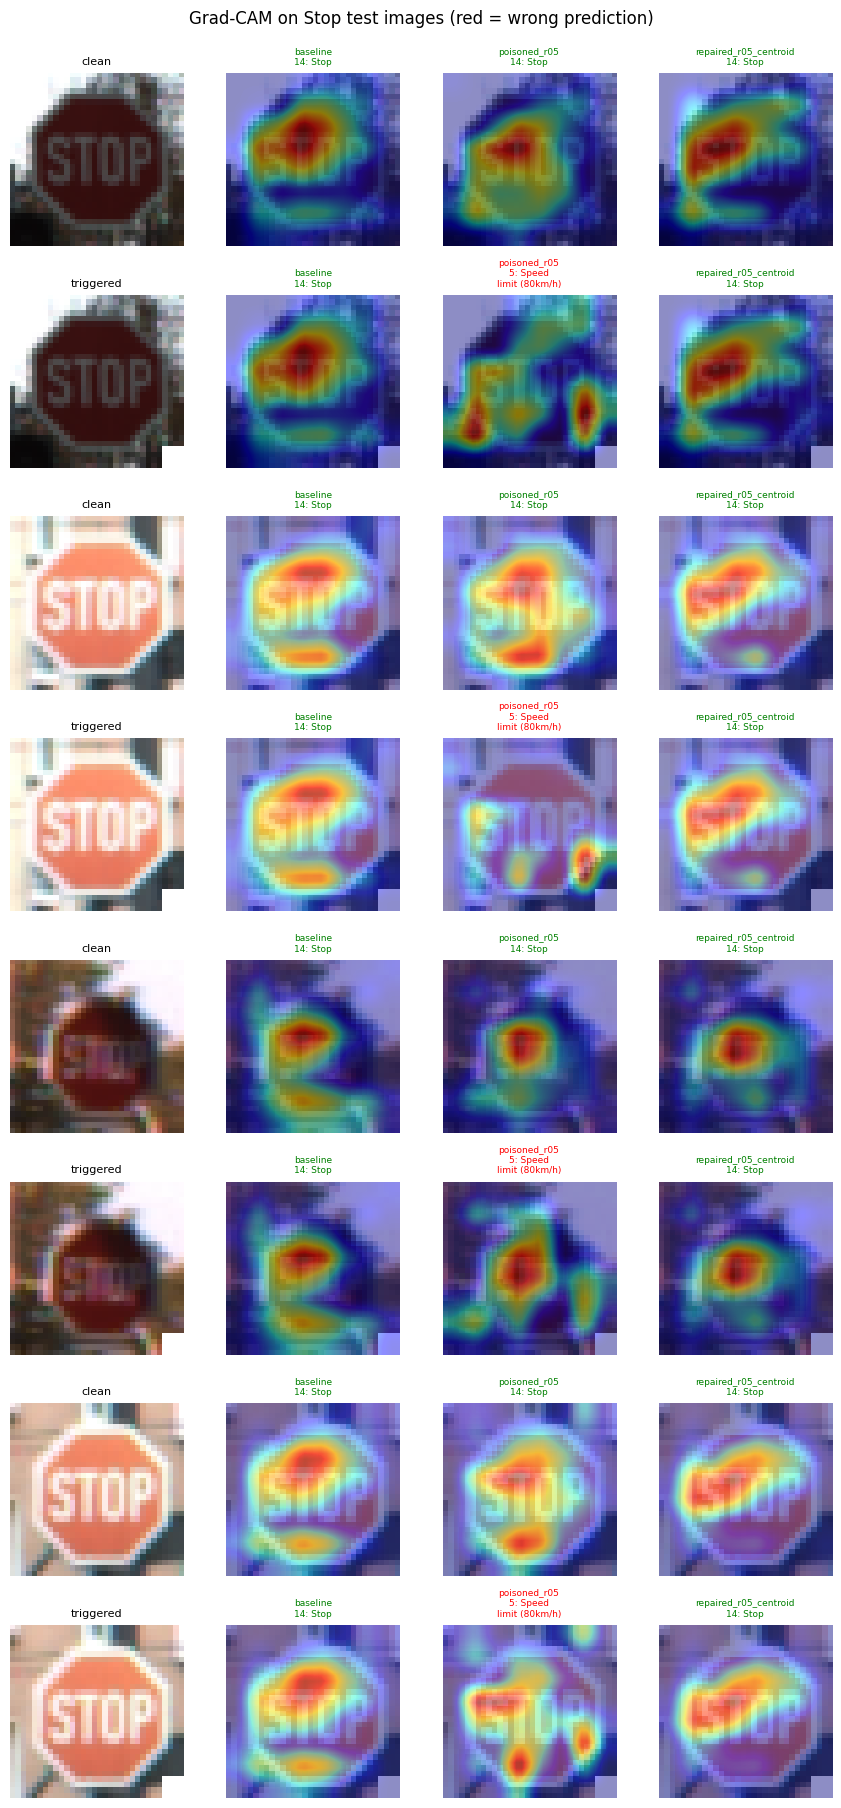

In [3]:
heatmaps, predictions = {}, {}
for name, model in models.items():
    heatmaps[name] = (grad_cam(model, x_stop, batch_size), grad_cam(model, x_stop_triggered, batch_size))
    predictions[name] = (predict(model, x_stop, batch_size)[0], predict(model, x_stop_triggered, batch_size)[0])

shown = np.sort(np.random.default_rng(cfg["seed"]).choice(len(x_stop), cfg["explain"]["n_gradcam_images"], replace=False))
plot_gradcam_comparison(
    x_stop[shown], x_stop_triggered[shown],
    {n: (clean[shown], trig[shown]) for n, (clean, trig) in heatmaps.items()},
    {n: (clean[shown], trig[shown]) for n, (clean, trig) in predictions.items()},
    source, GTSRB_CLASS_NAMES, figures_dir / "gradcam_comparison.png",
);

### Attention on the trigger corner

`trigger_attention` gives the share of each heatmap's total mass inside the bottom-right 8x8 square (the 4x4 trigger plus a 4-pixel margin, `explain.attention_region`). This square is 6.25% of the image: a heatmap spread evenly over the image would give 6.25%. Mean over all Stop test images, clean and triggered.

INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/trigger_attention.png


,clean,triggered,clean_median,triggered_median,triggered_pred_stop,triggered_pred_target
model,,,,,,
baseline,0.0184,0.0210,0.0172,0.0195,1.0000,0.0000
poisoned_r05,0.0144,0.0446,0.0131,0.0439,0.0593,0.9407
repaired_r05_centroid,0.0178,0.0078,0.0147,0.0071,1.0000,0.0000


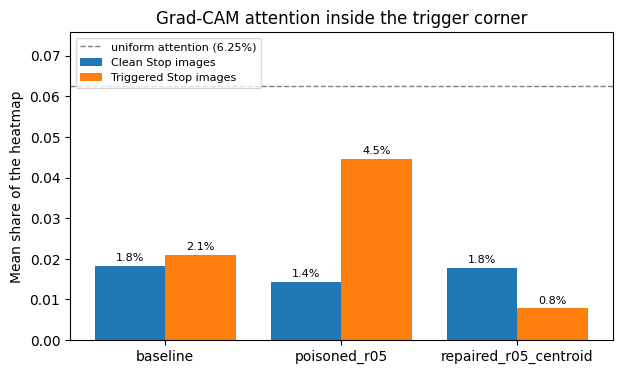

In [4]:
region = cfg["explain"]["attention_region"]
uniform_share = region**2 / (x_stop.shape[-2] * x_stop.shape[-1])
attention_rows = []
for name, (clean, trig) in heatmaps.items():
    clean_att, trig_att = trigger_attention(clean, cfg), trigger_attention(trig, cfg)
    attention_rows.append({
        "model": name,
        "clean": float(clean_att.mean()), "triggered": float(trig_att.mean()),
        "clean_median": float(np.median(clean_att)), "triggered_median": float(np.median(trig_att)),
        "triggered_pred_stop": float((predictions[name][1] == source).mean()),
        "triggered_pred_target": float((predictions[name][1] == target).mean()),
    })
plot_trigger_attention(attention_rows, uniform_share, figures_dir / "trigger_attention.png")
pd.DataFrame(attention_rows).set_index("model").round(4)

**What the measures show.**
- On clean Stop images, the three models look at the sign itself (the octagon and the letters). Only 1.4% to 1.8% of the heatmap mass falls in the bottom-right 8x8 corner, well below the 6.25% that uniform attention would give.
- On triggered Stop images:
  - The **baseline** barely changes: 2.1% in the corner, and it still predicts Stop for 100% of the images.
  - The **poisoned model** predicts Speed limit 80 for 94.1% of them. Its attention in the corner triples, from 1.4% to 4.5% (median 4.4%).
  - The **repaired model** predicts Stop for 100% of them, and its corner attention drops to 0.8%.
- In the four examples, the poisoned model's heatmap on triggered images moves away from the centre of the sign. Hot spots appear near the bottom-right corner, and also elsewhere on the image border.

**Limits of the picture.**
- The heatmap is computed on 8x8 feature maps, so it is coarse. The hot spot sits next to the trigger rather than exactly on it.
- The corner share stays below 6.25% even for the poisoned model, because the attention is spread over several places.
- Grad-CAM shows where the class score is sensitive. It does not prove that the trigger alone causes the prediction. The ASR measured in notebook 03 is the direct proof of that.

## 2. t-SNE of the hidden-layer activations

The points are the **training** images of the 5% poisoned training set whose label is Stop or Speed limit 80, in three groups: clean Stop, clean Speed limit 80, and the poisoned images (labelled Speed limit 80, really Stop + trigger). Their 256-unit hidden-layer activations (`model.features`, the layer used by the detection methods) are reduced with PCA to 50 dimensions, then embedded in 2D with t-SNE (seeded).

The same points are embedded twice: with the poisoned model and with the baseline. The two embeddings are separate runs, so their axes cannot be compared; only the relative positions inside a panel matter. t-SNE also distorts distances between groups. **It is a display tool only and is never used for detection decisions.**

INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/tsne_poisoned_r05.png


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/tsne_baseline_vs_poisoned.png


{'clean Stop': 456,
 'clean Speed limit 80': 1140,
 'poisoned (label 80, Stop + trigger)': 24}

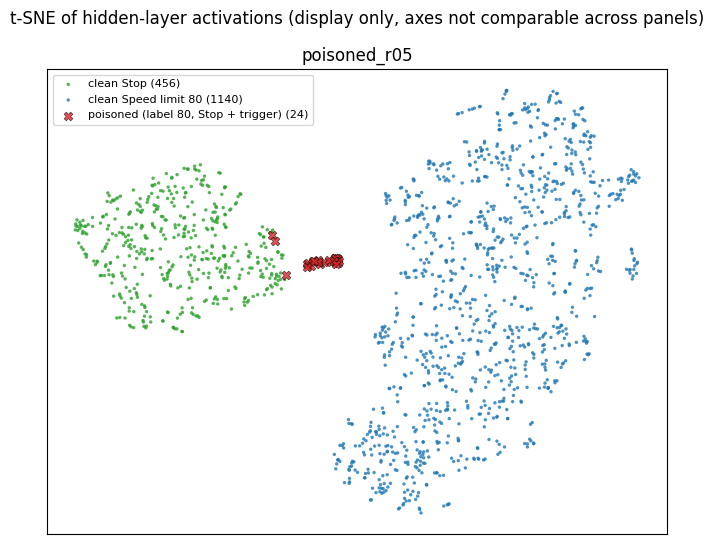

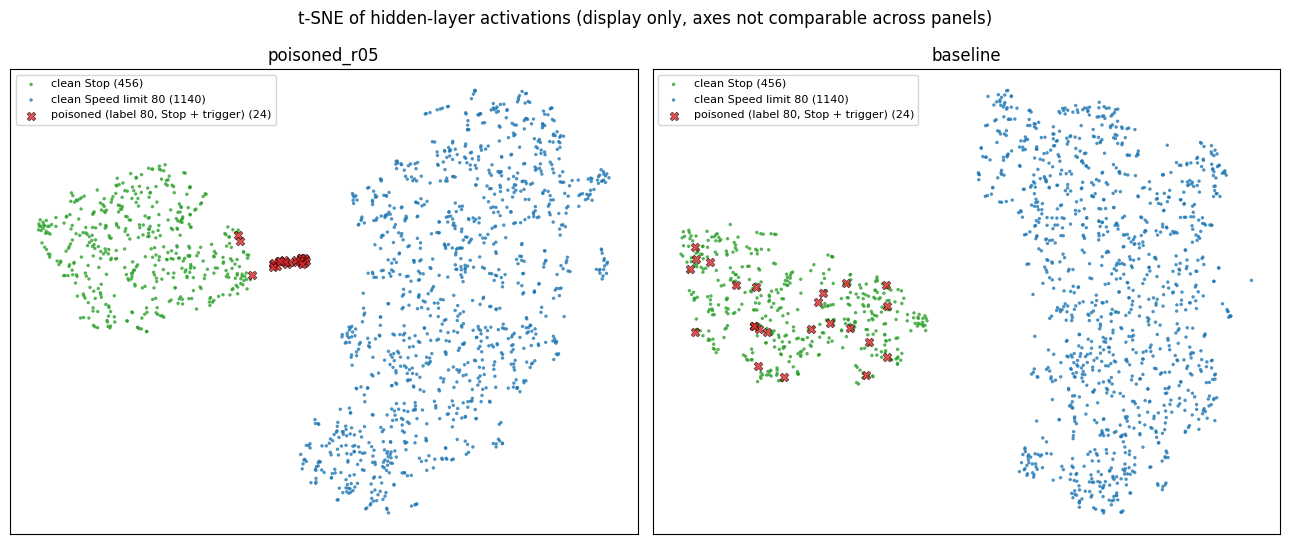

In [5]:
keep = np.flatnonzero(np.isin(y_poisoned, [source, target]))
is_poison = np.isin(keep, record["indices"])
groups = np.where(is_poison, 2, np.where(y_poisoned[keep] == source, 0, 1))
group_names = ["clean Stop", "clean Speed limit 80", "poisoned (label 80, Stop + trigger)"]
embeddings = {
    name: tsne_embedding(get_activations(models[name], x_poisoned[keep], batch_size), cfg, cfg["seed"])
    for name in (poisoned_name, "baseline")
}
plot_tsne({poisoned_name: embeddings[poisoned_name]}, groups, group_names, figures_dir / "tsne_poisoned_r05.png")
plot_tsne(embeddings, groups, group_names, figures_dir / "tsne_baseline_vs_poisoned.png")
counts = {name: int((groups == g).sum()) for g, name in enumerate(group_names)}
counts

In [6]:
save_json({
    "note": "display only, never used for detection decisions",
    "parameters": cfg["explain"],
    "uniform_share": uniform_share,
    "n_stop_test_images": int(len(x_stop)),
    "trigger_attention": attention_rows,
    "tsne_points": counts,
}, metrics_dir / "explanations.json")

INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/explanations.json


**Where the poisoned images land.**
- With the **poisoned model**, 21 of the 24 poisoned images form a tight group of their own. The group lies between the clean Stop images and the clean Speed limit 80 images, separated from the large Speed limit 80 mass. The other 3 sit at the edge of the clean Stop group.
- With the **baseline**, which never saw the trigger with label 80, the same 24 images are scattered among the clean Stop images. For a clean model they are ordinary Stop signs, and the small white square changes little.
- So the backdoor creates a separate representation for "Stop + trigger", and the poisoned model maps it to class 80. (The 21/3 split is read from the figure; t-SNE does not preserve distances exactly.)

**Link to activation clustering (notebook 04).**
- Activation clustering relies on exactly this: inside the samples labelled 80, the poisoned images form a separate group in the hidden layer.
- But the group holds 24 points against 1,140 clean ones, which is 2.1% of the class (dilution). With 2-means, splitting the large and spread-out clean mass of class 80 in two reduces the within-cluster distance more than isolating 24 points. The clustering therefore cuts the clean mass, and the method finds none of the 24 poisoned images.
- The group being far from the class-80 centre is also why distance to centroid found 15 of the 24.
- This figure is a 2D display of a 256-dimensional space. It explains the detection results; it was not used to make or tune any detection.

## 3. Conclusion

The two tools show the backdoor from two sides:
- **Grad-CAM, on the image.** Only the poisoned model changes its attention when the trigger is added. Its mass in the trigger corner goes from 1.4% to 4.5% while it predicts Speed limit 80 for 94.1% of the triggered Stop images. The baseline (2.1%) and the repaired model (0.8%) keep predicting Stop and do not shift their attention to the corner.
- **t-SNE, in the hidden layer.** The poisoned model gives "Stop + trigger" a compact representation of its own, separate from both clean classes. The baseline mixes these images with the clean Stop images.

That compact group is what activation-based detection tries to find. At 5% it is only 24 points among the 1,164 samples labelled 80, which is why clustering misses it.

Both views are qualitative and come from one training run per model and one trigger. They are coarse: Grad-CAM works on 8x8 maps, and t-SNE distorts distances. They help explain the measured results but do not replace the ASR and detection metrics.